# SafeDrive Insurance Claim Prediction
## Notebook 1 — Data preprocessing, EDA and feature engineering

**Business objective.** Help SafeDrive Insurance Ltd. understand which observable vehicle and policy characteristics are associated with claim filing, then create a reproducible modelling dataset. The target is `is_claim` (0 = no claim, 1 = claim filed).

**Business questions**
1. How do claim rates vary across driver age, vehicle age and population-density groups?
2. Are safety features, vehicle segment, fuel type and speed-alert status associated with different observed claim rates?
3. Can a leakage-safe model identify higher-risk policies better than a naive classification rule?

**Success measures.** Operationally, the analysis should produce reproducible policy-level scores, interpretable risk segments and a documented model comparison. For model quality, prioritize ROC-AUC and recall/F1 alongside precision because claims are a minority class. These are association and prediction analyses, not causal conclusions.

### 1. Imports and robust dataset loading

In [39]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = Path("/mnt/data/SafeDrive_Capstone") if Path("/mnt/data/SafeDrive_Capstone").exists() else NOTEBOOK_DIR.parent
CANDIDATE_PATHS = [
    NOTEBOOK_DIR / "dataset.csv",
    NOTEBOOK_DIR.parent / "dataset.csv",
    NOTEBOOK_DIR.parent / "data" / "dataset.csv",
    Path("/mnt/data/dataset.csv"),
    Path("/mnt/data/SafeDrive_Capstone/data/dataset.csv"),
    Path("/mnt/user-data/uploads/dataset.csv"),
]
DATA_PATH = next((path for path in CANDIDATE_PATHS if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "dataset.csv was not found. Put it beside this notebook or in ../data/."
    )
OUT_DIR = PROJECT_DIR / "outputs" / "stage1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Dataset path:", DATA_PATH.resolve())
df_raw = pd.read_csv(DATA_PATH)
print("Dataset shape:", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes.to_frame("dtype"))

Dataset path: /content/dataset.csv
Dataset shape: (58592, 44)


,policy_id,policy_tenure,age_of_car,age_of_policyholder,area_cluster,population_density,make,segment,model,fuel_type,...,is_brake_assist,is_power_door_locks,is_central_locking,is_power_steering,is_driver_seat_height_adjustable,is_day_night_rear_view_mirror,is_ecw,is_speed_alert,ncap_rating,is_claim
0,ID00001,0.515874,0.05,0.644231,C1,4990,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
1,ID00002,0.672619,0.02,0.375000,C2,27003,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
2,ID00003,0.841110,0.02,0.384615,C3,4076,1,A,M1,CNG,...,No,No,No,Yes,No,No,No,Yes,0,0
3,ID00004,0.900277,0.11,0.432692,C4,21622,1,C1,M2,Petrol,...,Yes,Yes,Yes,Yes,Yes,Yes,Yes,Yes,2,0
4,ID00005,0.596403,0.11,0.634615,C5,34738,2,A,M3,Petrol,...,No,Yes,Yes,Yes,No,Yes,Yes,Yes,2,0


,dtype
policy_id,object
policy_tenure,float64
age_of_car,float64
age_of_policyholder,float64
area_cluster,object
population_density,int64
make,int64
segment,object
model,object
fuel_type,object


### 2. Data quality profile
We first inspect schema, missingness, duplicates and target imbalance before changing the data.

In [40]:
print("Data-type counts:")
display(df_raw.dtypes.value_counts().rename_axis("dtype").to_frame("column_count"))
print("\nMissing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate policy_id values:", df_raw["policy_id"].duplicated().sum())
print("\nTarget counts:")
display(df_raw["is_claim"].value_counts(dropna=False).sort_index().to_frame("count"))
print("\nTarget proportions:")
display(df_raw["is_claim"].value_counts(normalize=True).sort_index().to_frame("proportion"))
claim_rate = df_raw["is_claim"].mean()
print(f"Overall observed claim rate: {claim_rate:.4%}")

Data-type counts:


,column_count
dtype,
object,28
int64,12
float64,4



Missing values by column:


,missing_count
policy_id,0
policy_tenure,0
age_of_car,0
age_of_policyholder,0
area_cluster,0
population_density,0
make,0
segment,0
model,0
fuel_type,0


Exact duplicate rows: 0
Duplicate policy_id values: 0

Target counts:


,count
is_claim,
0,54844
1,3748



Target proportions:


,proportion
is_claim,
0,0.936032
1,0.063968


Overall observed claim rate: 6.3968%


### 3. Remove exact duplicate rows and standardize binary flags
Duplicate policy IDs are reported but not automatically removed: duplicate IDs may require business investigation.

In [41]:
df_clean = df_raw.drop_duplicates().copy()
print("Rows before exact-duplicate removal:", len(df_raw))
print("Rows after exact-duplicate removal:", len(df_clean))
print("Repeated policy IDs after row removal:", df_clean["policy_id"].duplicated().sum())

# Detect object columns whose non-missing values are exclusively Yes/No labels.
yes_no_columns = []
for column in df_clean.select_dtypes(include="object").columns:
    values = set(df_clean[column].dropna().astype(str).str.strip().str.title().unique())
    if values and values.issubset({"Yes", "No"}):
        yes_no_columns.append(column)

for column in yes_no_columns:
    df_clean[column] = df_clean[column].astype("string").str.strip().str.title()

print("Detected Yes/No columns:", yes_no_columns)
for column in yes_no_columns:
    print(column, sorted(df_clean[column].dropna().unique().tolist()))

Rows before exact-duplicate removal: 58592
Rows after exact-duplicate removal: 58592
Repeated policy IDs after row removal: 0
Detected Yes/No columns: ['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']
is_esc ['No', 'Yes']
is_adjustable_steering ['No', 'Yes']
is_tpms ['No', 'Yes']
is_parking_sensors ['No', 'Yes']
is_parking_camera ['No', 'Yes']
is_front_fog_lights ['No', 'Yes']
is_rear_window_wiper ['No', 'Yes']
is_rear_window_washer ['No', 'Yes']
is_rear_window_defogger ['No', 'Yes']
is_brake_assist ['No', 'Yes']
is_power_door_locks ['No', 'Yes']
is_central_locking ['No', 'Yes']
is_power_steering ['No', 'Yes']
is_driver_seat_height_adjustable ['No', 'Yes']
is_day_night_

### 4. Extract numeric engine specifications
`extract_leading_number` returns the first numeric token and safely handles missing or unexpected strings.

In [42]:
def extract_leading_number(value):
    """Extract the first integer/decimal number from a text value."""
    import re
    if pd.isna(value):
        return np.nan
    match = re.search(r"[-+]?\d*\.?\d+", str(value))
    return float(match.group()) if match else np.nan

df_clean["max_power_bhp"] = df_clean["max_power"].apply(extract_leading_number)
df_clean["max_torque_nm"] = df_clean["max_torque"].apply(extract_leading_number)
# Preserve useful engine-speed information as additional engineered columns.
df_clean["power_rpm"] = df_clean["max_power"].astype("string").str.extract(r"@(\d+)\s*rpm", expand=False)
df_clean["torque_rpm"] = df_clean["max_torque"].astype("string").str.extract(r"@(\d+)\s*rpm", expand=False)
df_clean["power_rpm"] = pd.to_numeric(df_clean["power_rpm"], errors="coerce")
df_clean["torque_rpm"] = pd.to_numeric(df_clean["torque_rpm"], errors="coerce")
display(df_clean[["max_power", "max_power_bhp", "max_torque", "max_torque_nm"]].head())

,max_power,max_power_bhp,max_torque,max_torque_nm
0,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
1,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
2,40.36bhp@6000rpm,40.36,60Nm@3500rpm,60.0
3,88.50bhp@6000rpm,88.50,113Nm@4400rpm,113.0
4,67.06bhp@5500rpm,67.06,91Nm@4250rpm,91.0


### 5. Correct types and handle missing values
For this descriptive Stage 1 export, numeric missing values use medians and categorical missing values use modes. Modeling notebooks will fit imputers on training data only.

In [43]:
for column in df_clean.columns:
    if column in ["policy_id", "max_power", "max_torque"]:
        continue
    if df_clean[column].dtype == "object" and column not in yes_no_columns:
        converted = pd.to_numeric(df_clean[column], errors="coerce")
        if converted.notna().sum() == df_clean[column].notna().sum():
            df_clean[column] = converted

numeric_columns = df_clean.select_dtypes(include=np.number).columns.tolist()
for column in numeric_columns:
    if column == "is_claim":
        continue
    median_value = df_clean[column].median()
    if pd.isna(median_value):
        median_value = 0
    df_clean[column] = df_clean[column].fillna(median_value)

categorical_columns = df_clean.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for column in categorical_columns:
    mode_values = df_clean[column].mode(dropna=True)
    fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
    df_clean[column] = df_clean[column].fillna(fill_value)

print("Missing values remaining:", int(df_clean.isna().sum().sum()))

Missing values remaining: 0


### 6. IQR outlier capping and binary encoding
IQR capping is applied to numeric predictors except the target and binary flag-like columns. This is a descriptive cleaning step; model preprocessing is still fitted on training data only.

In [44]:
flag_columns = [column for column in yes_no_columns if column in df_clean.columns]
for column in df_clean.select_dtypes(include=np.number).columns:
    if column == "is_claim" or column in flag_columns:
        continue
    q1 = df_clean[column].quantile(0.25)
    q3 = df_clean[column].quantile(0.75)
    iqr = q3 - q1
    if pd.notna(iqr) and iqr > 0:
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        df_clean[column] = df_clean[column].clip(lower, upper)

for column in flag_columns:
    df_clean[column] = df_clean[column].map({"Yes": 1, "No": 0}).astype("int64")

remaining_yes_no = []
for column in df_clean.select_dtypes(include=["object", "string"]).columns:
    values = set(df_clean[column].dropna().astype(str).str.strip().str.title().unique())
    if values.intersection({"Yes", "No"}):
        remaining_yes_no.append(column)
print("Unexpected Yes/No strings remaining:", remaining_yes_no)

Unexpected Yes/No strings remaining: []


### 7. One-hot encoded analysis export
This export is provided to satisfy the explicit encoding requirement. The modeling pipeline later uses raw nominal categories and performs one-hot encoding inside the training-only `ColumnTransformer`, avoiding double encoding.

In [45]:
nominal_columns = [
    "area_cluster", "segment", "fuel_type", "engine_type",
    "rear_brakes_type", "transmission_type", "steering_type"
]
available_nominal_columns = [c for c in nominal_columns if c in df_clean.columns]
df_encoded_export = pd.get_dummies(
    df_clean, columns=available_nominal_columns, drop_first=False, dtype=int
)
encoded_path = OUT_DIR / "cleaned_encoded_analysis.csv"
df_encoded_export.to_csv(encoded_path, index=False)
print("Encoded analysis export:", encoded_path.resolve())
print("Encoded shape:", df_encoded_export.shape)

Encoded analysis export: /outputs/stage1/cleaned_encoded_analysis.csv
Encoded shape: (58592, 90)


### 8. Univariate EDA
The plots below use actual values from the supplied dataset. Categorical plots are based on cleaned, readable categories.

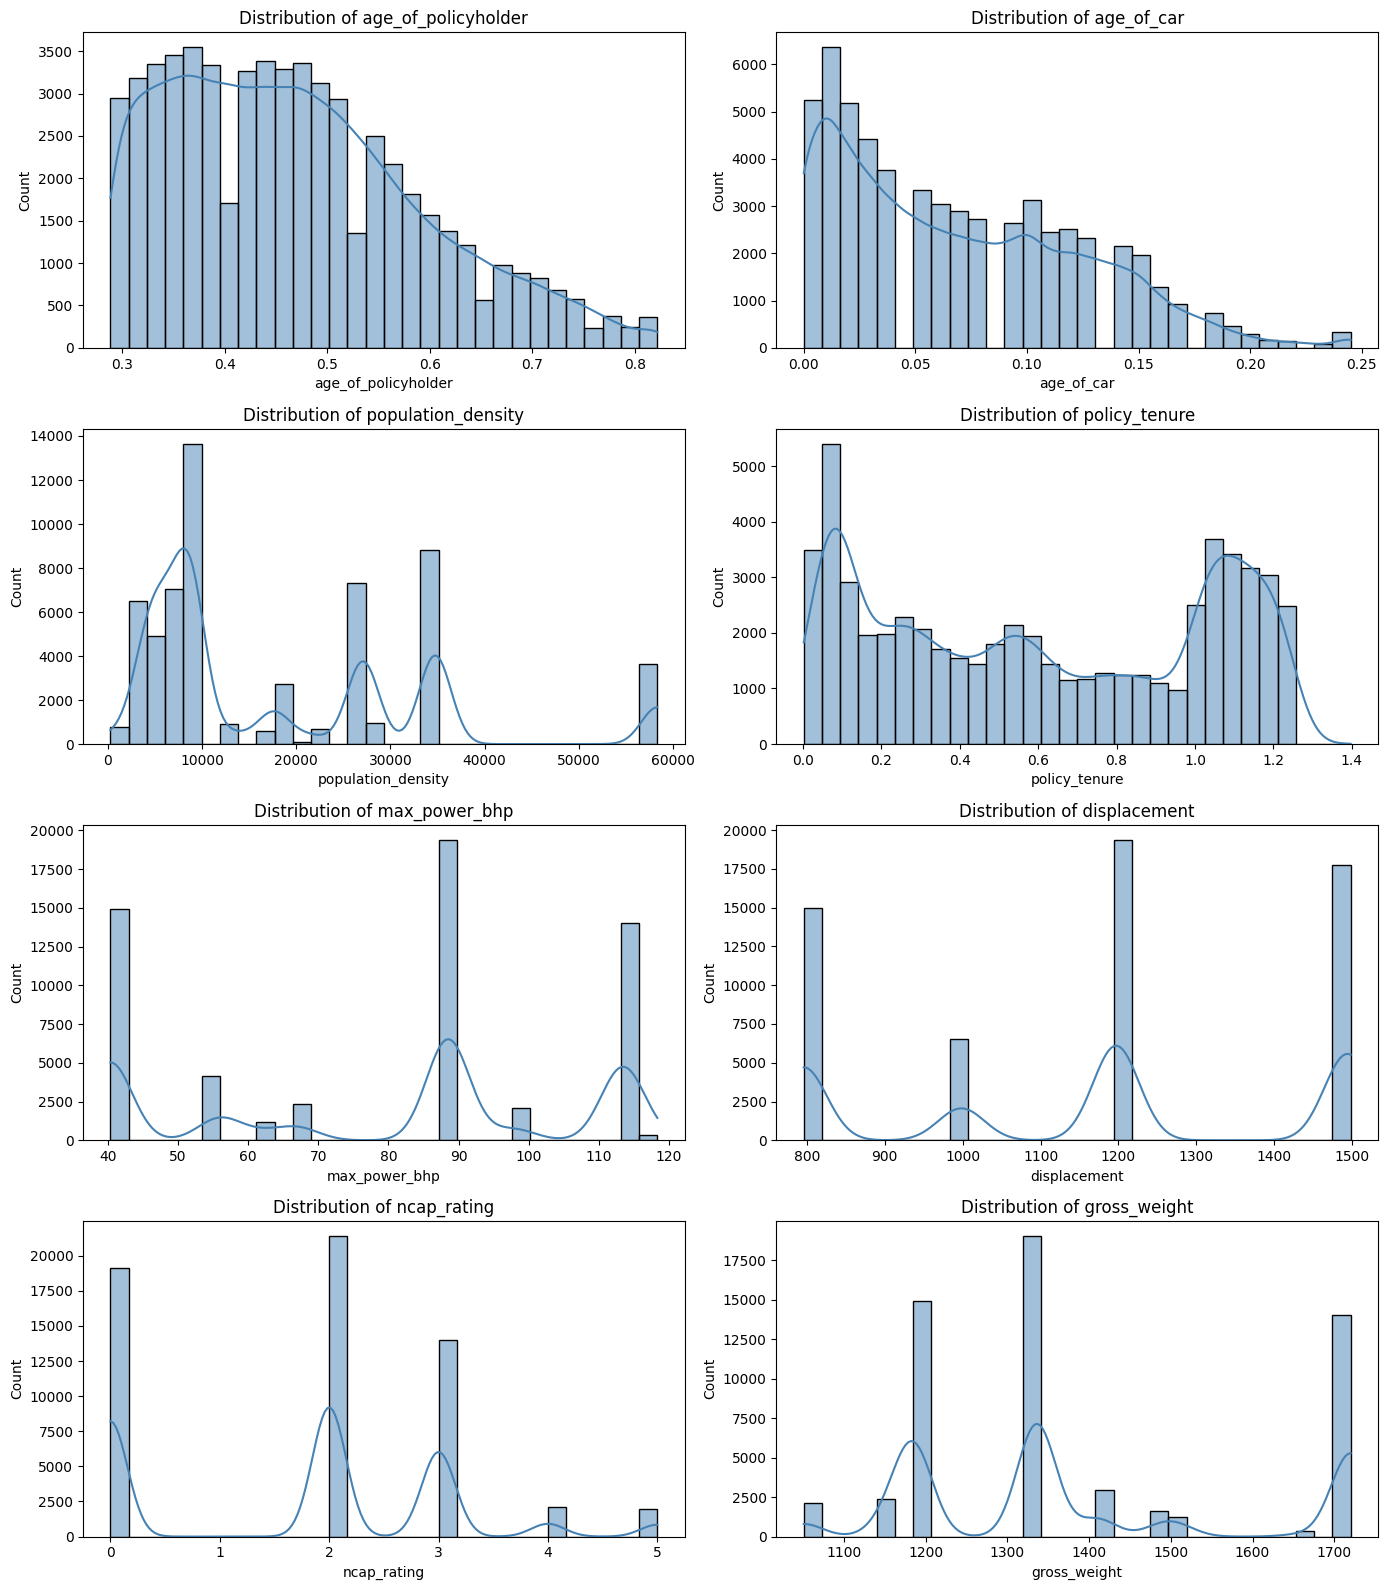

In [46]:
numeric_plot_features = [
    "age_of_policyholder", "age_of_car", "population_density", "policy_tenure",
    "max_power_bhp", "displacement", "ncap_rating", "gross_weight"
]
numeric_plot_features = [c for c in numeric_plot_features if c in df_clean.columns]
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
for axis, column in zip(axes.flat, numeric_plot_features):
    sns.histplot(data=df_clean, x=column, bins=30, kde=True, color="steelblue", ax=axis)
    axis.set_title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

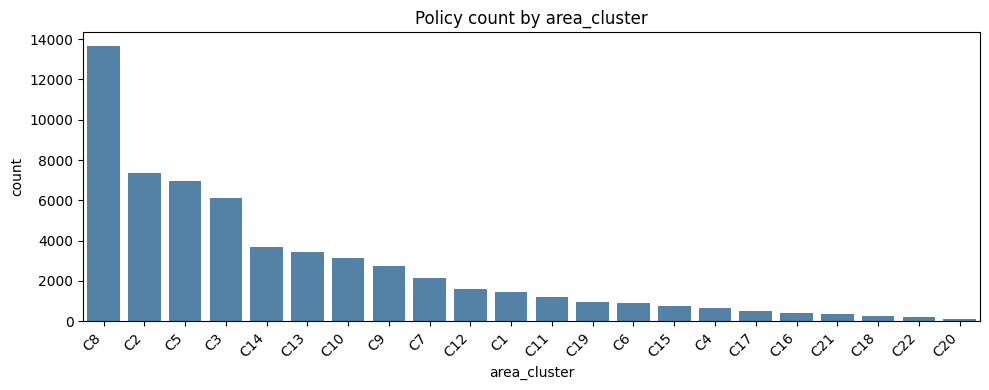

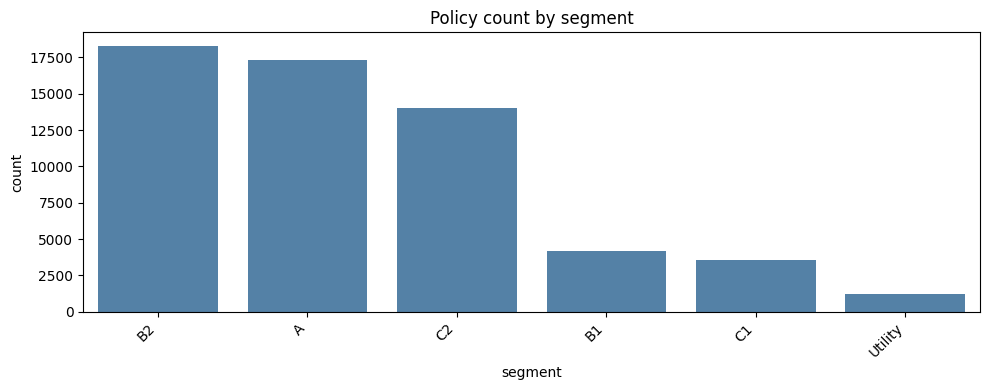

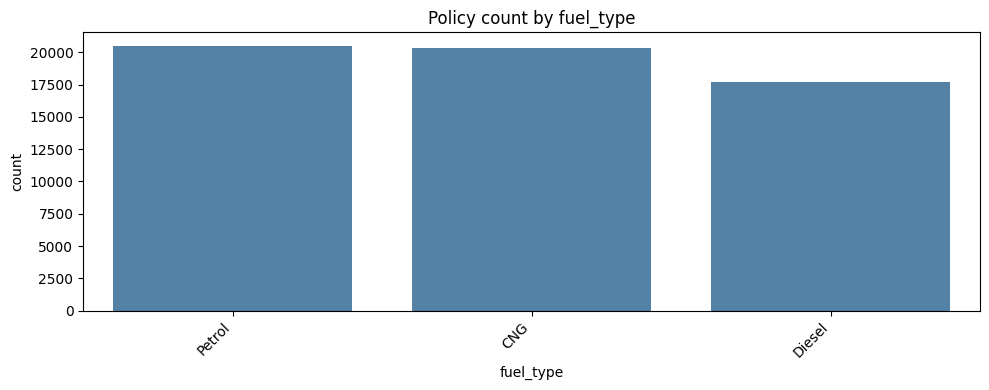

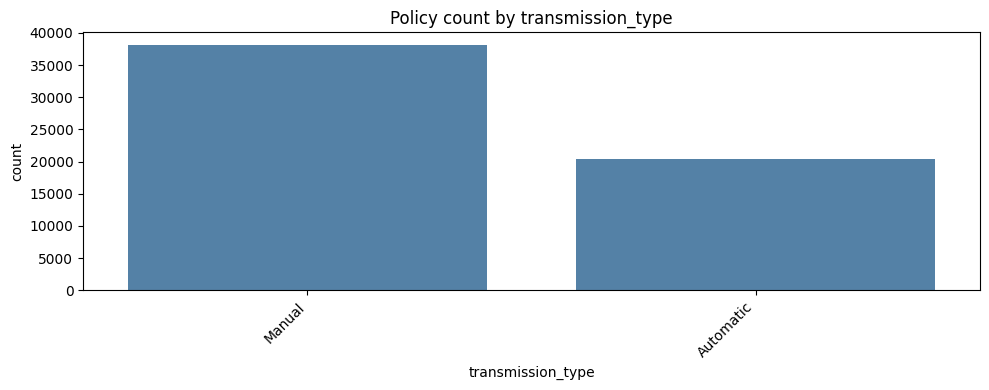

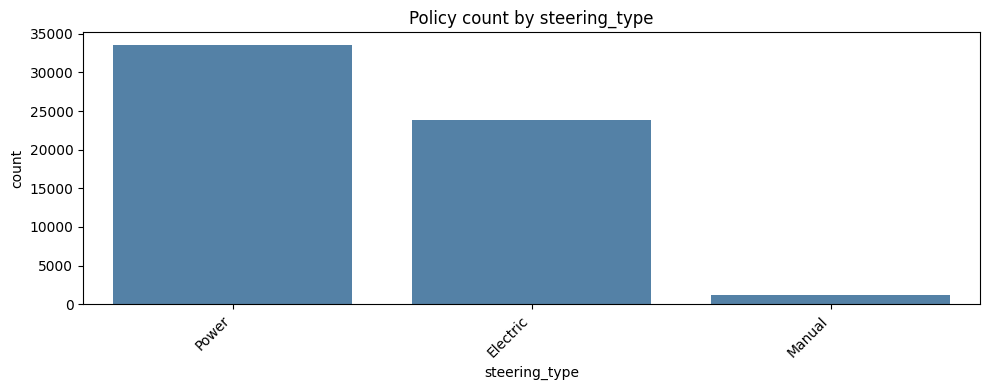

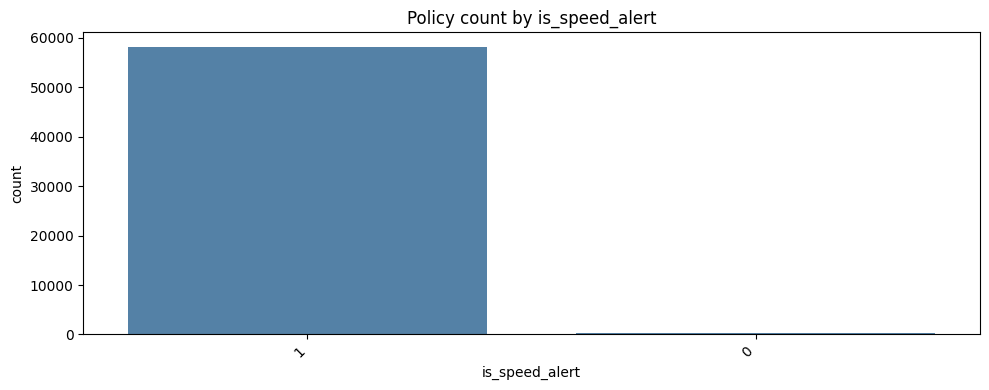

In [47]:
categorical_plot_features = [
    "area_cluster", "segment", "fuel_type", "transmission_type",
    "steering_type", "is_speed_alert"
]
categorical_plot_features = [c for c in categorical_plot_features if c in df_clean.columns]
for column in categorical_plot_features:
    plt.figure(figsize=(10, 4))
    order = df_clean[column].value_counts().index
    sns.countplot(data=df_clean, x=column, order=order, color="steelblue")
    plt.title(f"Policy count by {column}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

### 9. Bivariate EDA — claim rates by quintiles and categories

,age_of_policyholder_quintile,policy_count,claim_rate
0,"(0.287, 0.356]",12932,0.055908
1,"(0.356, 0.423]",11855,0.061071
2,"(0.423, 0.49]",11598,0.068288
3,"(0.49, 0.567]",10530,0.065147
4,"(0.567, 0.822]",11677,0.070480


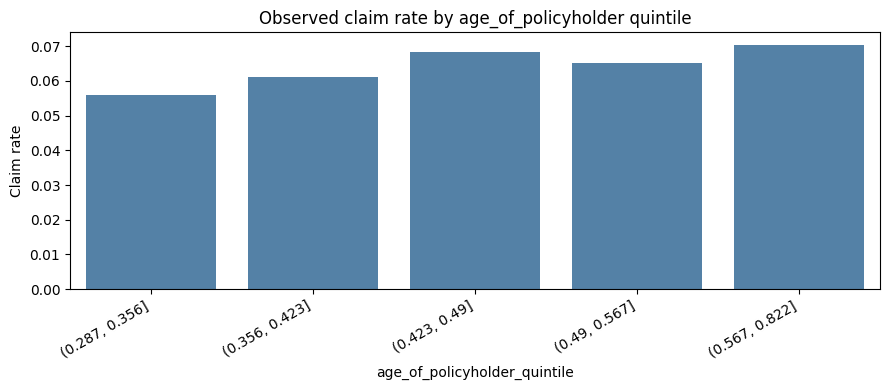

,age_of_car_quintile,policy_count,claim_rate
0,"(-0.001, 0.02]",16808,0.069431
1,"(0.02, 0.04]",8178,0.063585
2,"(0.04, 0.08]",12013,0.067593
3,"(0.08, 0.12]",10714,0.065428
4,"(0.12, 0.245]",10879,0.050372


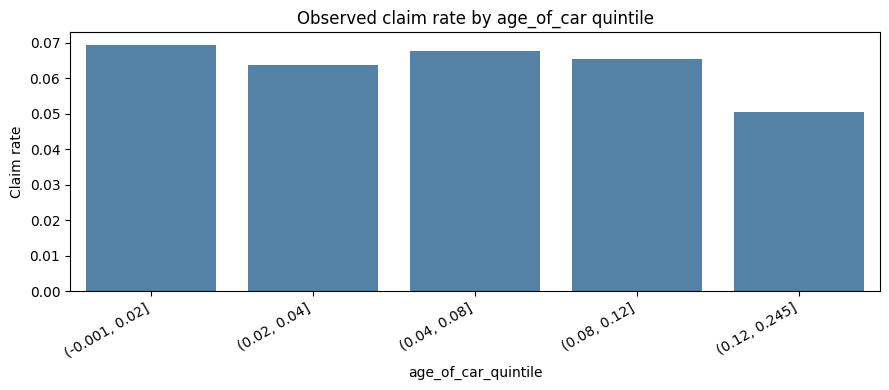

,population_density_quintile,policy_count,claim_rate
0,"(289.999, 5410.0]",12142,0.063499
1,"(5410.0, 8794.0]",20693,0.068429
2,"(8794.0, 17804.0]",4232,0.054584
3,"(17804.0, 34738.0]",16047,0.065433
4,"(34738.0, 58339.5]",5478,0.051114


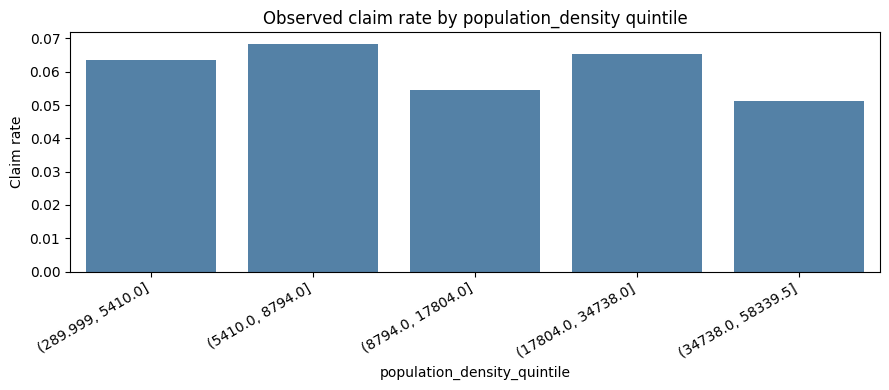

In [48]:
quintile_features = ["age_of_policyholder", "age_of_car", "population_density"]
claim_rate_tables = {}
for column in quintile_features:
    df_clean[column + "_quintile"] = pd.qcut(
        df_clean[column], q=5, duplicates="drop"
    )
    rate_table = df_clean.groupby(column + "_quintile", observed=False)["is_claim"].agg(
        policy_count="size", claim_rate="mean"
    ).reset_index()
    claim_rate_tables[column] = rate_table
    display(rate_table)
    plt.figure(figsize=(9, 4))
    sns.barplot(data=rate_table, x=column + "_quintile", y="claim_rate", color="steelblue")
    plt.title(f"Observed claim rate by {column} quintile")
    plt.ylabel("Claim rate")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

,is_speed_alert,policy_count,claim_rate
1,1,58229,0.064109
0,0,363,0.041322


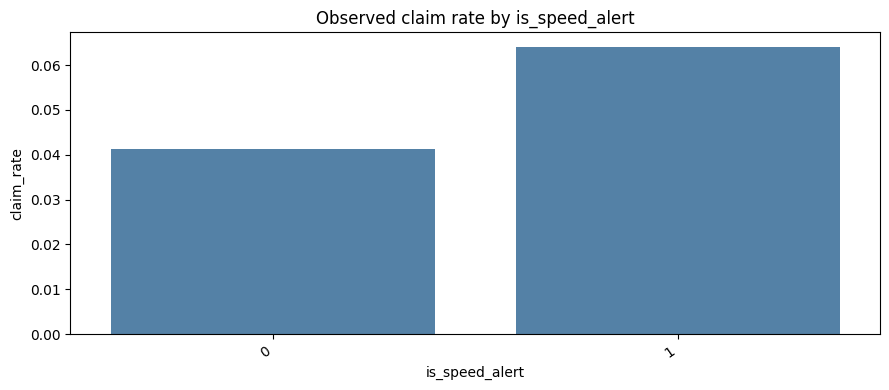

,segment,policy_count,claim_rate
2,B2,18314,0.068581
4,C2,14018,0.064275
3,C1,3557,0.064099
0,A,17321,0.060389
5,Utility,1209,0.060380
1,B1,4173,0.058471


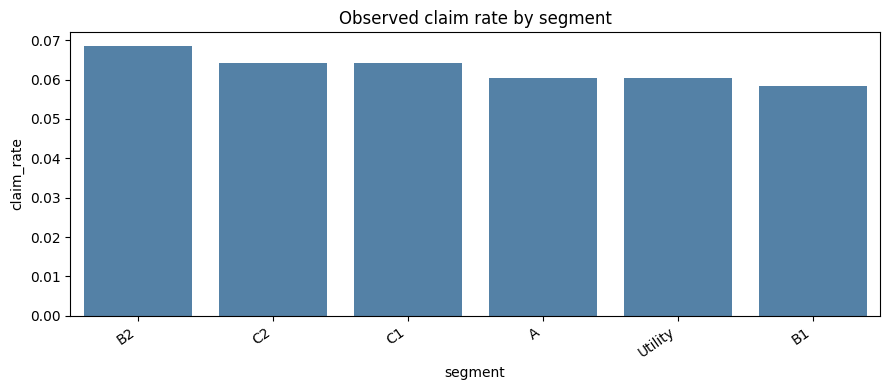

,fuel_type,policy_count,claim_rate
2,Petrol,20532,0.066384
1,Diesel,17730,0.064862
0,CNG,20330,0.060748


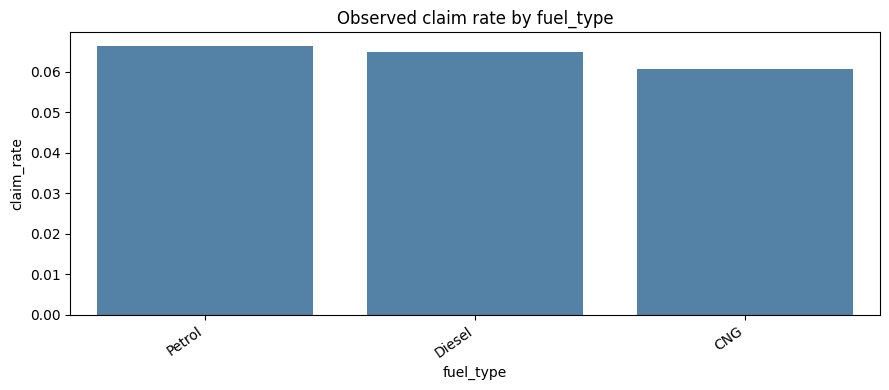

,transmission_type,policy_count,claim_rate
0,Automatic,20411,0.064181
1,Manual,38181,0.063854


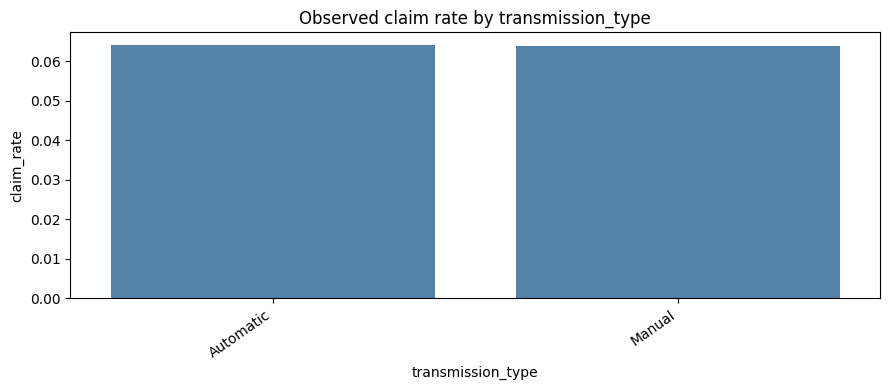

In [49]:
for column in ["is_speed_alert", "segment", "fuel_type", "transmission_type"]:
    if column not in df_clean.columns:
        continue
    rate_table = df_clean.groupby(column, observed=False)["is_claim"].agg(
        policy_count="size", claim_rate="mean"
    ).reset_index().sort_values("claim_rate", ascending=False)
    display(rate_table)
    plt.figure(figsize=(9, 4))
    sns.barplot(data=rate_table, x=column, y="claim_rate", color="steelblue")
    plt.title(f"Observed claim rate by {column}")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

### 10. Correlation analysis
Pearson correlation measures linear association and does not establish causation.

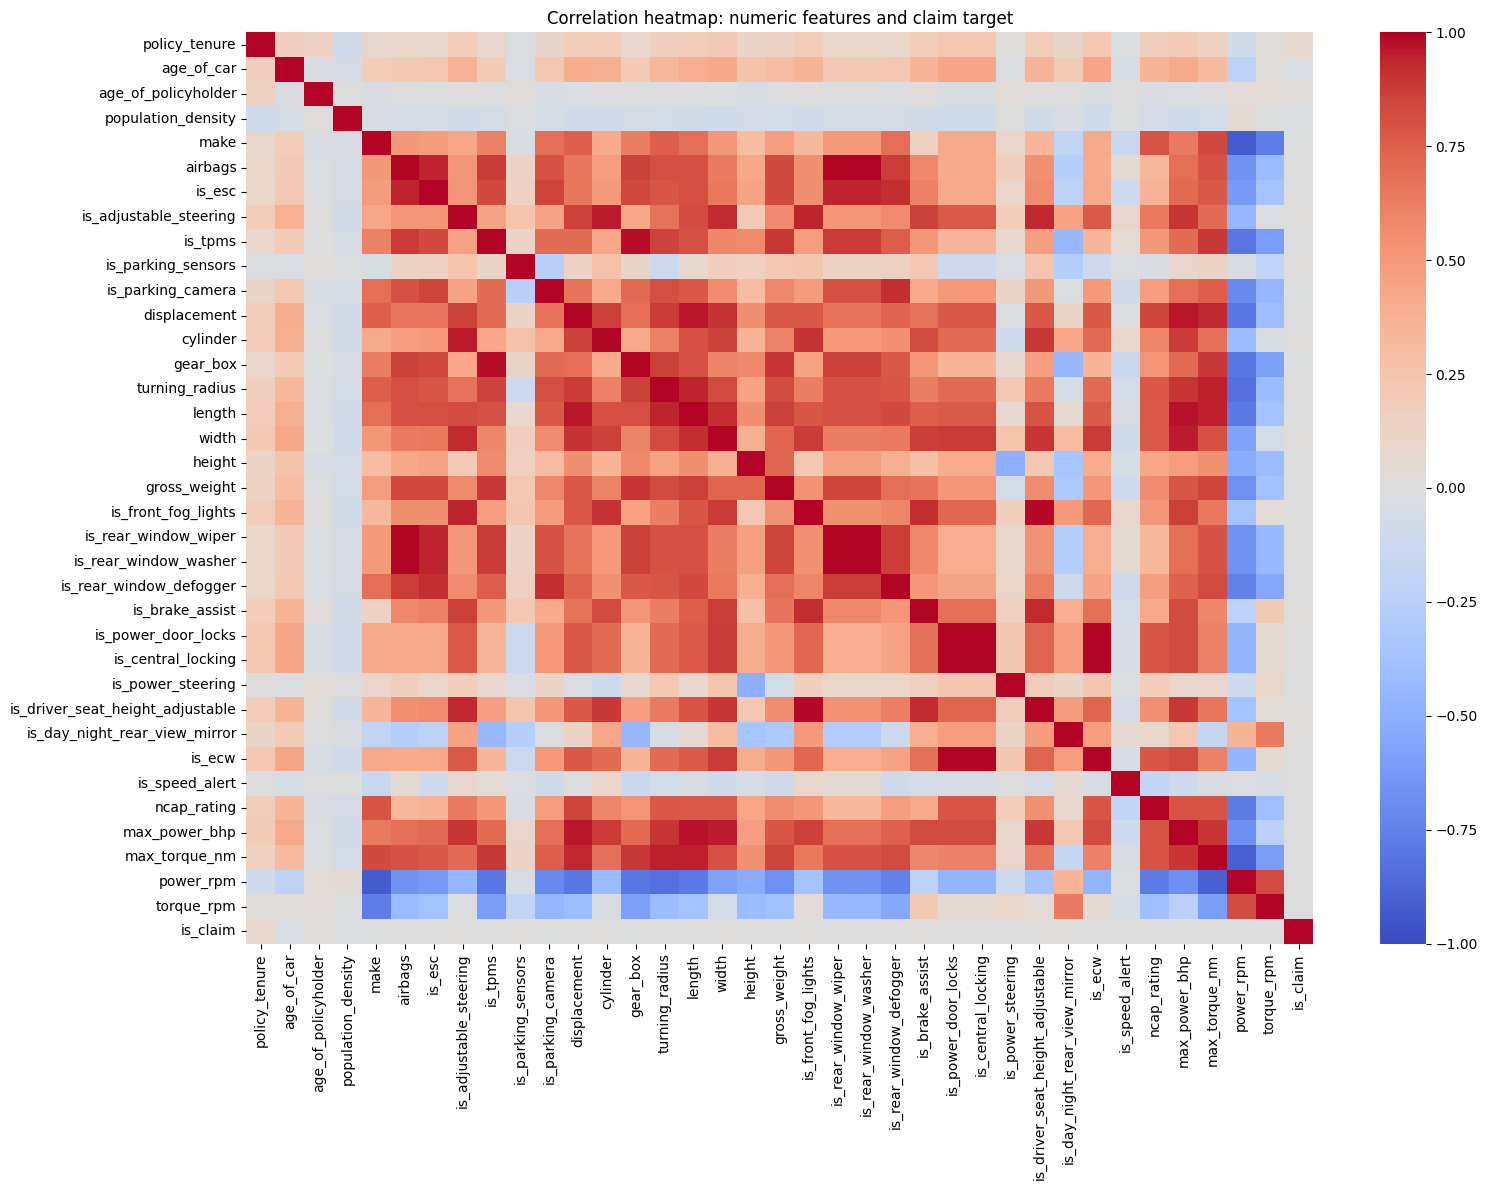

,correlation,absolute_correlation
policy_tenure,0.078747,0.078747
age_of_car,-0.028175,0.028175
age_of_policyholder,0.022318,0.022318
population_density,-0.016609,0.016609
is_adjustable_steering,0.013917,0.013917
cylinder,0.013434,0.013434
is_front_fog_lights,0.011825,0.011825
is_brake_assist,0.010893,0.010893
is_driver_seat_height_adjustable,0.010686,0.010686
width,0.009947,0.009947


In [50]:
numeric_features = df_clean.select_dtypes(include=np.number).columns.tolist()
numeric_features = [c for c in numeric_features if c not in ["is_claim"]]
correlation_columns = numeric_features + ["is_claim"]
correlation_matrix = df_clean[correlation_columns].corr(numeric_only=True)
plt.figure(figsize=(16, 12))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation heatmap: numeric features and claim target")
plt.tight_layout()
plt.show()

target_correlations = (
    correlation_matrix["is_claim"].drop("is_claim").dropna()
    .to_frame("correlation")
)
target_correlations["absolute_correlation"] = target_correlations["correlation"].abs()
target_correlations = target_correlations.sort_values("absolute_correlation", ascending=False)
display(target_correlations)

### 11. Business-relevant feature engineering
`High_Risk_Driver_Flag` is a rubric-defined proxy, not a validated underwriting rule. `safety_equipment_count` sums all detected Yes/No safety flags. `power_to_weight_ratio` is bhp divided by gross weight.

In [51]:
age_q25 = df_clean["age_of_policyholder"].quantile(0.25)
df_clean["High_Risk_Driver_Flag"] = (
    (df_clean["age_of_policyholder"] <= age_q25) &
    (df_clean["ncap_rating"] <= 2)
).astype(int)

safety_columns = [
    c for c in yes_no_columns
    if c in df_clean.columns and c != "is_claim"
]
df_clean["safety_equipment_count"] = df_clean[safety_columns].sum(axis=1)

df_clean["power_to_weight_ratio"] = (
    df_clean["max_power_bhp"] / df_clean["gross_weight"].replace(0, np.nan)
)
df_clean["power_to_weight_ratio"] = (
    df_clean["power_to_weight_ratio"].replace([np.inf, -np.inf], np.nan).fillna(0)
)
print("Age 25th percentile:", age_q25)
print("Safety flags included:", safety_columns)
display(df_clean[[
    "High_Risk_Driver_Flag", "safety_equipment_count",
    "max_power_bhp", "gross_weight", "power_to_weight_ratio"
]].describe())

Age 25th percentile: 0.365384615384615
Safety flags included: ['is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert']


,High_Risk_Driver_Flag,safety_equipment_count,max_power_bhp,gross_weight,power_to_weight_ratio
count,58592.000000,58592.000000,58592.000000,58592.000000,58592.000000
mean,0.171320,9.678437,78.976765,1385.276813,0.056021
std,0.376792,5.153804,27.699259,212.423085,0.015706
min,0.000000,2.000000,40.360000,1051.000000,0.034059
25%,0.000000,3.000000,40.360000,1185.000000,0.034059
50%,0.000000,11.000000,88.500000,1335.000000,0.065959
75%,0.000000,16.000000,97.890000,1510.000000,0.066292
max,1.000000,16.000000,118.360000,1720.000000,0.093140


### 12. Correlation redundancy review and VIF
The rubric asks for absolute correlations greater than 0.9 and VIF values above 10. The correlation filter below uses a stable rule: for each redundant pair, retain the first feature in dataset order and document the removed partner. VIF is calculated on numeric predictors only.

In [52]:
model_excluded = {"policy_id", "is_claim"}
numeric_predictors = [
    c for c in df_clean.select_dtypes(include=np.number).columns
    if c not in model_excluded
]
numeric_corr = df_clean[numeric_predictors].corr().abs()
upper = numeric_corr.where(np.triu(np.ones(numeric_corr.shape), k=1).astype(bool))
high_corr_pairs = []
drop_redundant_numeric = set()
for column in upper.columns:
    for other_column in upper.index:
        value = upper.loc[other_column, column]
        if pd.notna(value) and value > 0.90:
            high_corr_pairs.append((other_column, column, float(value)))
            # Stable rule: drop the later column in dataset-order traversal.
            drop_redundant_numeric.add(column)

print("Pairs with |correlation| > 0.90:")
display(pd.DataFrame(high_corr_pairs, columns=["feature_1", "feature_2", "abs_correlation"]))
print("Dropped by correlation rule:", sorted(drop_redundant_numeric))

Pairs with |correlation| > 0.90:


,feature_1,feature_2,abs_correlation
0,airbags,is_esc,0.941230
1,is_adjustable_steering,cylinder,0.957287
2,is_tpms,gear_box,0.983270
3,displacement,length,0.961655
4,turning_radius,length,0.944899
5,is_adjustable_steering,width,0.928007
6,length,width,0.915918
7,is_adjustable_steering,is_front_fog_lights,0.945062
8,cylinder,is_front_fog_lights,0.904696
9,airbags,is_rear_window_wiper,0.997013


Dropped by correlation rule: ['cylinder', 'gear_box', 'is_brake_assist', 'is_central_locking', 'is_driver_seat_height_adjustable', 'is_ecw', 'is_esc', 'is_front_fog_lights', 'is_rear_window_defogger', 'is_rear_window_washer', 'is_rear_window_wiper', 'length', 'max_power_bhp', 'max_torque_nm', 'power_rpm', 'safety_equipment_count', 'width']


In [53]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

vif_candidates = [c for c in numeric_predictors if c not in drop_redundant_numeric]
X_vif = df_clean[vif_candidates].replace([np.inf, -np.inf], np.nan).fillna(0).astype(float)
# Remove constant columns because VIF is not meaningful for them.
vif_candidates = [c for c in vif_candidates if X_vif[c].nunique() > 1]
X_vif = X_vif[vif_candidates]
X_vif_const = add_constant(X_vif, has_constant="add")
vif_rows = []
for column in vif_candidates:
    try:
        value = variance_inflation_factor(X_vif_const.values, X_vif_const.columns.get_loc(column))
    except Exception:
        value = np.inf
    vif_rows.append({"feature": column, "VIF": value})
vif_table = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False)
display(vif_table)
print("Features with VIF > 10:")
display(vif_table[vif_table["VIF"] > 10])

/tmp/ipykernel_984/3532505382.py:13: UserWarning: The design matrix is poorly conditioned (condition number=2.67e+16). VIF calculations may be numerically unstable.
  value = variance_inflation_factor(X_vif_const.values, X_vif_const.columns.get_loc(column))
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-pac

,feature,VIF
4,make,1.000800e+15
5,airbags,1.000800e+15
9,is_parking_camera,1.000800e+15
8,is_parking_sensors,1.000800e+15
7,is_tpms,1.000800e+15
6,is_adjustable_steering,1.000800e+15
14,is_power_door_locks,1.000800e+15
15,is_power_steering,1.000800e+15
16,is_day_night_rear_view_mirror,1.000800e+15
17,is_speed_alert,1.000800e+15


Features with VIF > 10:


,feature,VIF
4,make,1.000800e+15
5,airbags,1.000800e+15
9,is_parking_camera,1.000800e+15
8,is_parking_sensors,1.000800e+15
7,is_tpms,1.000800e+15
6,is_adjustable_steering,1.000800e+15
14,is_power_door_locks,1.000800e+15
15,is_power_steering,1.000800e+15
16,is_day_night_rear_view_mirror,1.000800e+15
17,is_speed_alert,1.000800e+15


### 13. Final feature set and saved Stage 1 artifacts
The modeling features exclude the policy identifier and target. Nominal categories remain as categories for the Stage 2 pipeline; binary flags are already numeric. The VIF review informs numeric retention, while categorical predictors are retained for modeling.

In [54]:
numeric_keep = [c for c in numeric_predictors if c not in drop_redundant_numeric]
# Keep numeric variables with VIF > 10 in the record; remove only the highly redundant
# correlation partners by the documented rule rather than blindly dropping all high-VIF fields.
categorical_keep = [
    c for c in df_clean.select_dtypes(include=["object", "string", "category"]).columns
    if c not in ["policy_id", "max_power", "max_torque"] and not c.endswith("_quintile")
]
final_modeling_features = list(dict.fromkeys(numeric_keep + categorical_keep))
final_modeling_features = [
    c for c in final_modeling_features if c in df_clean.columns and c not in ["policy_id", "is_claim"]
]
df_clean["policy_id"] = df_raw.loc[df_clean.index, "policy_id"].values
df_clean.to_csv(OUT_DIR / "cleaned_modeling_data.csv", index=False)
with open(OUT_DIR / "stage1_feature_manifest.json", "w") as file:
    json.dump({
        "target": "is_claim",
        "identifier": "policy_id",
        "final_modeling_features": final_modeling_features,
        "numeric_features": [c for c in final_modeling_features if c in numeric_keep],
        "categorical_features": [c for c in final_modeling_features if c in categorical_keep],
        "correlation_dropped_features": sorted(drop_redundant_numeric),
        "high_vif_features": vif_table.loc[vif_table["VIF"] > 10, "feature"].tolist()
    }, file, indent=2)
print("Cleaned modeling data saved.")
print("Final modeling feature count:", len(final_modeling_features))
print(final_modeling_features)

Cleaned modeling data saved.
Final modeling feature count: 30
['policy_tenure', 'age_of_car', 'age_of_policyholder', 'population_density', 'make', 'airbags', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'displacement', 'turning_radius', 'height', 'gross_weight', 'is_power_door_locks', 'is_power_steering', 'is_day_night_rear_view_mirror', 'is_speed_alert', 'ncap_rating', 'torque_rpm', 'High_Risk_Driver_Flag', 'power_to_weight_ratio', 'area_cluster', 'segment', 'model', 'fuel_type', 'engine_type', 'rear_brakes_type', 'transmission_type', 'steering_type']


### Interpretation: VIF results

Seventeen features show VIF values near 1e15, and statsmodels reports a rank-deficient design matrix (condition number 2.67e16). This indicates exact or near-exact linear dependence among vehicle-specification and safety-equipment columns, which are largely determined by the car model. The values should be read as "severely collinear" and not as precise estimates. The remaining features (policy_tenure, age_of_car, age_of_policyholder, population_density, High_Risk_Driver_Flag) have VIF below 2.

These features were flagged but not dropped automatically. Only highly correlated partners (|correlation| > 0.90) were removed by the documented rule. Collinearity can make logistic regression coefficients unstable, so the odds ratios in Notebook 2 should not be over-interpreted for these features. Tree-based models are not affected in the same way.

### Stage 1 interpretation notes
- The target is imbalanced: a model that predicts no claim for every policy would have high accuracy but zero claim recall.
- Claim-rate charts describe observed associations only; they do not establish that a feature causes claims.
- The high-risk flag follows the rubric's exact definition. Its business value must be validated out of sample before use in underwriting.
- Correlation and VIF are diagnostics, not automatic proof that a feature should be removed. The selected feature manifest records the reproducible choices.
- The saved CSV and JSON manifest are the hand-off artifacts for Notebook 2.